# Nuages de mots

**TP2 – année choisie : 1960**

Ce notebook crée un nuage de mots pour l'année 1960. Nous gardons la fonction `clean_text` du cours sans la modifier. Nous changeons seulement trois choses : l'année, le chemin vers les données et la liste de stopwords. Cette liste est enrichie en trois étapes, car chaque étape fait apparaître de nouveaux mots inutiles.

## Imports et stopwords

In [1]:
from collections import Counter
from wordcloud import WordCloud
import os
import nltk
nltk.download('stopwords')
from nltk.corpus import stopwords
from IPython.display import Image

[nltk_data] Downloading package stopwords to C:\Users\COMPUTER
[nltk_data]     STORES\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [2]:
# Stopwords (Idem que dans s1)
sw = stopwords.words("french")
sw += ["les", "plus", "cette", "fait", "faire", "être", "deux", "comme", "dont", "tout",
       "ils", "bien", "sans", "peut", "tous", "après", "ainsi", "donc", "cet", "sous",
       "celle", "entre", "encore", "toutes", "pendant", "moins", "dire", "cela", "non",
       "faut", "trois", "aussi", "dit", "avoir", "doit", "contre", "depuis", "autres",
       "van", "het", "autre", "jusqu", "ville", "rossel", "dem"]
sw = set(sw)
len(sw)

200

## Créer un fichier contenant le texte de tous les journaux d'une année donnée

In [3]:
# Choisir une année
year = 1960

In [4]:
# Lister les fichiers de cette année
# Le motif "_1960-" vise la date dans le nom du fichier
data_path = '../../data'
txt_path = '../../data/txt'
txts = [f for f in os.listdir(txt_path) if os.path.isfile(os.path.join(txt_path, f)) and f"_{year}-" in f]
len(txts)

100

In [5]:
# Stocker le contenu de ces fichiers dans une liste
content_list = []
for txt in txts:
    with open(os.path.join(txt_path, txt), 'r', encoding='utf-8') as f:
        content_list.append(f.read())

In [6]:
# Compter le nombre d'éléments (=fichiers) dans la liste
len(content_list)

100

In [7]:
# Imprimer les 200 premiers caractères du contenu du premier fichier
content_list[0][0:200]

"ia« le som ÏJsIne MéuhMrïiqii S.AT'BBirîï^^ J00, r. Merlu» Duché, Vllvorde ch. STENO-DACTYLO élément de let ordre, bilingue, bon- i ne rémunération. Situation d’avenir, i Candidat, A soumet par écrit "

In [8]:
# Ecrire tout le contenu dans un fichier temporaire
temp_path = '../../data/tmp'
if not os.path.exists(temp_path):
    os.mkdir(temp_path)
with open(os.path.join(temp_path, f'{year}.txt'), 'w', encoding='utf-8') as f:
    f.write(' '.join(content_list))

In [9]:
# Imprimer le contenu du fichier et constater les "déchets"
with open(os.path.join(temp_path, f'{year}.txt'), 'r', encoding='utf-8') as f:
    before = f.read()

before[:500]

'ia« le som ÏJsIne MéuhMrïiqii S.AT\'BBirîï^^ J00, r. Merlu» Duché, Vllvorde ch. STENO-DACTYLO élément de let ordre, bilingue, bon- i ne rémunération. Situation d’avenir, i Candidat, A soumet par écrit 130221H PORTANTE 80C.BRUXELL0I8I cherche pour entrée Immédiate Secrétaire Sténo-Dactylo 3 françalee - 1 an d\'expérience, al tuât h «table - semaine de 5 Jours. Ecrire é cur. vit et prêt Ag. Rossel 02983 H "âociËTS\'Importante de sa pi* demande 1 Sténo-Dactylo bilingue débutante. - Se présenter : 151.'

## Nettoyer le fichier à l'aide d'une fonction de nettoyage

### Créer la fonction de nettoyage (à adapter)

In [10]:
def clean_text(year, folder=None):
    if folder is None:
        input_path = f"{year}.txt"
        output_path = f"{year}_clean.txt"
    else:
        input_path = f"{folder}/{year}.txt"
        output_path = f"{folder}/{year}_clean.txt"
    output = open(output_path, "w", encoding='utf-8')
    with open(input_path, 'r', encoding='utf-8') as f:
        text = f.read()
        words = nltk.wordpunct_tokenize(text)
        kept = [w.upper() for w in words if len(w) > 2 and w.isalpha() and w.lower() not in sw]
        kept_string = " ".join(kept)
        output.write(kept_string)
    return f'Output has been written in {output_path}!'

### Appliquer la fonction sur le fichier complet de l'année

In [11]:
clean_text(year, folder=temp_path)

'Output has been written in ../../data/tmp/1960_clean.txt!'

In [12]:
# Vérifier le résultat
with open(os.path.join(temp_path, f'{year}_clean.txt'), 'r', encoding='utf-8') as f:
    after = f.read()

after[:500]

'SOM ÏJSINE MÉUHMRÏIQII BBIRÎÏ MERLU DUCHÉ VLLVORDE STENO DACTYLO ÉLÉMENT LET ORDRE BILINGUE BON RÉMUNÉRATION SITUATION AVENIR CANDIDAT SOUMET ÉCRIT PORTANTE CHERCHE ENTRÉE IMMÉDIATE SECRÉTAIRE STÉNO DACTYLO FRANÇALEE EXPÉRIENCE TUÂT TABLE SEMAINE JOURS ECRIRE CUR VIT PRÊT ÂOCIËTS IMPORTANTE DEMANDE STÉNO DACTYLO BILINGUE DÉBUTANTE PRÉSENTER RUE STALLE UCCLE IMPORTANTE CLE DELCO ASSURANCES DEMANDE INSPECTEUR PRODUCTEUR ACELDENTE INEENDLE VIE AGE ANS RÉSIDENCE OBLIGATOIRE AJOST AUDENAERDE ENVIRONS'

## Enrichir la liste de stopwords de manière itérative

### Itération 0 : la liste de départ

Nous regardons d'abord les mots les plus fréquents avec la liste de stopwords du cours (200 mots).

In [13]:
frequencies = Counter(after.split())
print(len(after.split()), "mots gardés")
print(frequencies.most_common(40))

277147 mots gardés
[('RUE', 1563), ('TÉL', 1204), ('BRUXELLES', 1112), ('ANS', 796), ('PRIX', 590), ('TRÈS', 545), ('BON', 466), ('APP', 451), ('DEMANDE', 426), ('PLACE', 412), ('ECR', 394), ('PRÉS', 387), ('BRUX', 386), ('GRAND', 384), ('SOIR', 379), ('ECRIRE', 374), ('MAISON', 357), ('BELGIQUE', 346), ('AGENCE', 343), ('BELGE', 333), ('HEURES', 330), ('PART', 328), ('TEMPS', 327), ('COURS', 317), ('MOIS', 304), ('AVANT', 296), ('CONGO', 294), ('BONNE', 293), ('PEU', 291), ('TRAV', 290), ('FRANCS', 288), ('TOUTE', 282), ('QUELQUES', 281), ('SERVICE', 277), ('PAYS', 277), ('JOURS', 274), ('AVENUE', 271), ('ANVERS', 270), ('LEURS', 269), ('PREMIÈRE', 266)]


**Commentaire.** Avec la liste de départ, il reste 277 147 mots. Les mots les plus fréquents sont « RUE » (1 563 fois), « TÉL » (1 204 fois) et « BRUXELLES » (1 112 fois). Ces mots viennent des adresses et des petites annonces. Ils cachent donc l'actualité : le premier mot vraiment lié à 1960, « CONGO », arrive seulement en 27e position avec 294 occurrences. Un nuage de mots construit maintenant montrerait surtout des annonces. Il faut donc enrichir la liste.

### Itération 1 : les abréviations et le vocabulaire des petites annonces

In [14]:
sw_annonces = ["tél", "tel", "téléph", "téléphone", "ecr", "ecrire", "écrire", "app", "appart", "brux", "trav", "enf",
       "mod", "fem", "culs", "vis", "conf", "réf", "référ", "références", "mat", "rem", "gar", "bat",
       "bur", "bel", "mén", "pers", "jne", "adr", "pet", "faç", "chf", "com", "int", "sem",
       "serv", "ouvr", "vend", "aven", "jrs", "jard", "ena", "num", "rez", "cuis", "sam", "frs",
       "terr", "sup", "sal", "ter", "comm", "grd", "den", "apr", "con", "pts", "lux", "vitae",
       "curriculum", "agence", "soir", "rue", "avenue", "chaussée", "étage", "prix", "francs", "offre", "demande", "cherche",
       "louer", "vendre", "vente", "ventes", "présenter", "adresser", "dactylo", "bilingue", "firme", "occasion", "conditions", "servante",
       "serveuse", "emploi", "personnel", "atelier", "garage", "villa", "auto", "notaire", "demeurant", "habitant", "stable", "satisfaction"]
sw |= set(sw_annonces)
len(sw)

296

In [15]:
# Itération 1 : nettoyer à nouveau et regarder les mots les plus fréquents
clean_text(year, folder=temp_path)
with open(os.path.join(temp_path, f'{year}_clean.txt'), 'r', encoding='utf-8') as f:
    after = f.read()
frequencies = Counter(after.split())
print(len(after.split()), "mots gardés")
print(frequencies.most_common(40))

260064 mots gardés
[('BRUXELLES', 1112), ('ANS', 796), ('TRÈS', 545), ('BON', 466), ('PLACE', 412), ('PRÉS', 387), ('GRAND', 384), ('MAISON', 357), ('BELGIQUE', 346), ('BELGE', 333), ('HEURES', 330), ('PART', 328), ('TEMPS', 327), ('COURS', 317), ('MOIS', 304), ('AVANT', 296), ('CONGO', 294), ('BONNE', 293), ('PEU', 291), ('TOUTE', 282), ('QUELQUES', 281), ('SERVICE', 277), ('PAYS', 277), ('JOURS', 274), ('ANVERS', 270), ('LEURS', 269), ('PREMIÈRE', 266), ('MME', 265), ('JEUNE', 264), ('JEAN', 258), ('MIDI', 253), ('TRAVAIL', 251), ('PREMIER', 250), ('LIBRE', 247), ('DIMANCHE', 247), ('GRANDE', 247), ('SAINT', 247), ('JUILLET', 247), ('SAMEDI', 246), ('DEVANT', 235)]


**Commentaire.** Nous avons ajouté 96 mots et il reste 260 064 mots, soit 17 083 de moins. Les abréviations des annonces ont disparu (« TÉL », « APP », « ECR »). En revanche, la tête du classement contient maintenant des mots très courants comme « ANS », « TRÈS », « BON » ou « GRAND ». Ces mots existent dans tous les textes, donc ils ne décrivent pas l'année 1960.

### Itération 2 : les mots courants sans contenu (adverbes, adjectifs, nombres, jours, mois)

In [16]:
sw_courants = ["ans", "très", "bon", "bonne", "bons", "bonnes", "grand", "grande", "grands", "petit", "petite", "gros",
       "beau", "belle", "peu", "trop", "fort", "mal", "mieux", "assez", "toute", "quelques", "quelque", "plusieurs",
       "chaque", "certains", "aucun", "seul", "seule", "leurs", "celui", "ceux", "elles", "laquelle", "avant", "devant",
       "vers", "chez", "près", "dès", "puis", "alors", "déjà", "toujours", "jamais", "souvent", "également", "enfin",
       "cependant", "parmi", "selon", "lors", "malgré", "surtout", "notamment", "seulement", "beaucoup", "tant", "autant", "quand",
       "parce", "car", "quant", "tandis", "ici", "loin", "tard", "ailleurs", "premier", "première", "deuxième", "troisième",
       "dernier", "dernière", "nouveau", "nouvelle", "quatre", "cinq", "six", "sept", "neuf", "demi", "quart", "cent",
       "temps", "heure", "heures", "jour", "jours", "journée", "matin", "midi", "semaine", "mois", "année", "années",
       "début", "fin", "suite", "partie", "part", "lieu", "place", "point", "vue", "effet", "cas", "cause",
       "raison", "rapport", "ordre", "nombre", "doute", "reste", "mise", "coup", "tour", "moment", "fois", "âge",
       "age", "lundi", "mardi", "mercredi", "jeudi", "vendredi", "samedi", "dimanche", "janvier", "février", "mars", "avril",
       "mai", "juin", "juillet", "août", "septembre", "octobre", "novembre", "décembre", "voir", "prendre", "mettre", "partir",
       "vient", "sait", "donné", "pris", "mis", "fit", "semble", "pourrait", "devait", "agit", "voici", "rien",
       "etc", "possible", "présent", "prés", "libre", "importante", "courant", "haut", "bas", "cher", "prêt", "divers",
       "environ", "actuellement", "pourquoi", "hui", "aujourd"]
sw |= set(sw_courants)
len(sw)

469

In [17]:
# Itération 2 : nettoyer à nouveau et regarder les mots les plus fréquents
clean_text(year, folder=temp_path)
with open(os.path.join(temp_path, f'{year}_clean.txt'), 'r', encoding='utf-8') as f:
    after = f.read()
frequencies = Counter(after.split())
print(len(after.split()), "mots gardés")
print(frequencies.most_common(40))

232651 mots gardés
[('BRUXELLES', 1112), ('MAISON', 357), ('BELGIQUE', 346), ('BELGE', 333), ('COURS', 317), ('CONGO', 294), ('SERVICE', 277), ('PAYS', 277), ('ANVERS', 270), ('MME', 265), ('JEUNE', 264), ('JEAN', 258), ('TRAVAIL', 251), ('SAINT', 247), ('ÉQUIPE', 223), ('MINISTRE', 217), ('SITUATION', 216), ('FRANCE', 215), ('ÉTAT', 212), ('BELGES', 210), ('CENTRE', 208), ('PARIS', 207), ('GÉNÉRAL', 195), ('FRANÇAIS', 193), ('HOMME', 193), ('GOUVERNEMENT', 191), ('ENFANTS', 187), ('DIVISION', 186), ('PRÉSIDENT', 186), ('LOUISE', 175), ('FEMME', 175), ('LOI', 175), ('VIE', 173), ('BUREAU', 173), ('SOCIÉTÉ', 170), ('VOITURE', 169), ('LIÈGE', 169), ('HOMMES', 165), ('MARCHÉ', 164), ('CONSEIL', 162)]


**Commentaire.** Nous avons ajouté 173 mots courants (adverbes, adjectifs, nombres, jours, mois). Il reste 232 651 mots. Le résultat devient lisible : « BELGIQUE », « BELGE » et « CONGO » sont dans les six premiers. Cependant, « BRUXELLES » reste largement en tête avec 1 112 occurrences, soit trois fois plus que « BELGIQUE » (346). Ce mot vient surtout des adresses, car Le Soir est un journal bruxellois. Il reste aussi des prénoms (« JEAN », « LOUISE ») et des civilités (« MME »).

### Itération 3 : les communes bruxelloises, les civilités et les prénoms

Nous retirons « Bruxelles » et ses communes, car elles viennent des adresses des annonces. Nous retirons aussi les civilités et les prénoms les plus fréquents, car un prénom seul ne permet pas de reconnaître une personne. C'est un choix : nous perdons l'information sur le lieu, mais nous gagnons en lisibilité.

In [18]:
sw_adresses = ["bruxelles", "uccle", "anderlecht", "ixelles", "schaerbeek", "forest", "jette", "mme", "monsieur", "dame", "dames", "homme",
       "hommes", "femme", "fille", "jeune", "jeunes", "jean", "pierre", "louis", "paul", "jacques", "georges", "andré",
       "albert", "marie", "louise", "max", "henri", "robert", "joseph", "saint", "maison", "centre", "service", "bureau",
       "porte", "entrée", "cours", "série", "serie", "iii"]
sw |= set(sw_adresses)
len(sw)

511

In [19]:
# Itération 3 : appliquer le nettoyage final
clean_text(year, folder=temp_path)

'Output has been written in ../../data/tmp/1960_clean.txt!'

In [20]:
# Vérifier le résultat final
with open(os.path.join(temp_path, f'{year}_clean.txt'), 'r', encoding='utf-8') as f:
    after = f.read()

after[:500]

'SOM ÏJSINE MÉUHMRÏIQII BBIRÎÏ MERLU DUCHÉ VLLVORDE STENO ÉLÉMENT LET RÉMUNÉRATION SITUATION AVENIR CANDIDAT SOUMET ÉCRIT PORTANTE IMMÉDIATE SECRÉTAIRE STÉNO FRANÇALEE EXPÉRIENCE TUÂT TABLE CUR VIT ÂOCIËTS STÉNO DÉBUTANTE STALLE CLE DELCO ASSURANCES INSPECTEUR PRODUCTEUR ACELDENTE INEENDLE VIE RÉSIDENCE OBLIGATOIRE AJOST AUDENAERDE ENVIRONS APPOINTEMENTS RAIS ROUTE BARÈME RAIS VOITURE JURCOMNILSSLONS SITUATION AVENIR ÉLÉMENT DYNAMIQUE TRAVAILLEUR VLTAE PHARMACIEN DTNDUSTRIE INTÉRIM EED LABORATOIR'

## Nuage de mots

### Afficher les termes les plus fréquents

In [21]:
frequencies = Counter(after.split())
print(len(after.split()), "mots gardés")
print(frequencies.most_common(50))

225519 mots gardés
[('BELGIQUE', 346), ('BELGE', 333), ('CONGO', 294), ('PAYS', 277), ('ANVERS', 270), ('TRAVAIL', 251), ('ÉQUIPE', 223), ('MINISTRE', 217), ('SITUATION', 216), ('FRANCE', 215), ('ÉTAT', 212), ('BELGES', 210), ('PARIS', 207), ('GÉNÉRAL', 195), ('FRANÇAIS', 193), ('GOUVERNEMENT', 191), ('ENFANTS', 187), ('DIVISION', 186), ('PRÉSIDENT', 186), ('LOI', 175), ('VIE', 173), ('SOCIÉTÉ', 170), ('VOITURE', 169), ('LIÈGE', 169), ('MARCHÉ', 164), ('CONSEIL', 162), ('MONDE', 162), ('MILLIONS', 156), ('NAMUR', 155), ('COUR', 150), ('NORD', 149), ('MATCH', 146), ('OUVRIER', 146), ('ROUTE', 145), ('EAU', 145), ('TRAVAUX', 141), ('CHAMBRE', 140), ('AFFAIRES', 139), ('CHEF', 138), ('COMMERCE', 136), ('SALLE', 135), ('MORT', 134), ('FORCE', 133), ('GAND', 133), ('ETAT', 133), ('POLITIQUE', 133), ('VICTOIRE', 129), ('NUIT', 129), ('COURSE', 127), ('AIDE', 125)]


**Commentaire.** La liste finale contient 511 stopwords, contre 200 au départ. Il reste 225 519 mots sur 277 147. Nous avons donc retiré 51 628 mots, soit environ 19 % du texte nettoyé. Ce chiffre est important : près d'un mot sur cinq n'apportait aucune information sur l'année.

Le classement final montre trois thèmes :
- **la politique belge et le Congo** : « BELGIQUE » (346), « BELGE » (333), « CONGO » (294), « MINISTRE » (217), « GOUVERNEMENT » (191). « CONGO » est le troisième mot de l'année. Il passe de la 27e à la 3e place grâce au nettoyage ;
- **le travail et l'économie** : « TRAVAIL » (251), « SOCIÉTÉ » (170), « MARCHÉ » (164), « OUVRIER » (146). Ces mots viennent en partie des offres d'emploi, mais aussi des articles sur les grèves et la loi unique ;
- **le sport** : « ÉQUIPE » (223), « DIVISION » (186), « MATCH » (146), « VICTOIRE » (129).

### Créer, stocker et afficher le nuage de mots

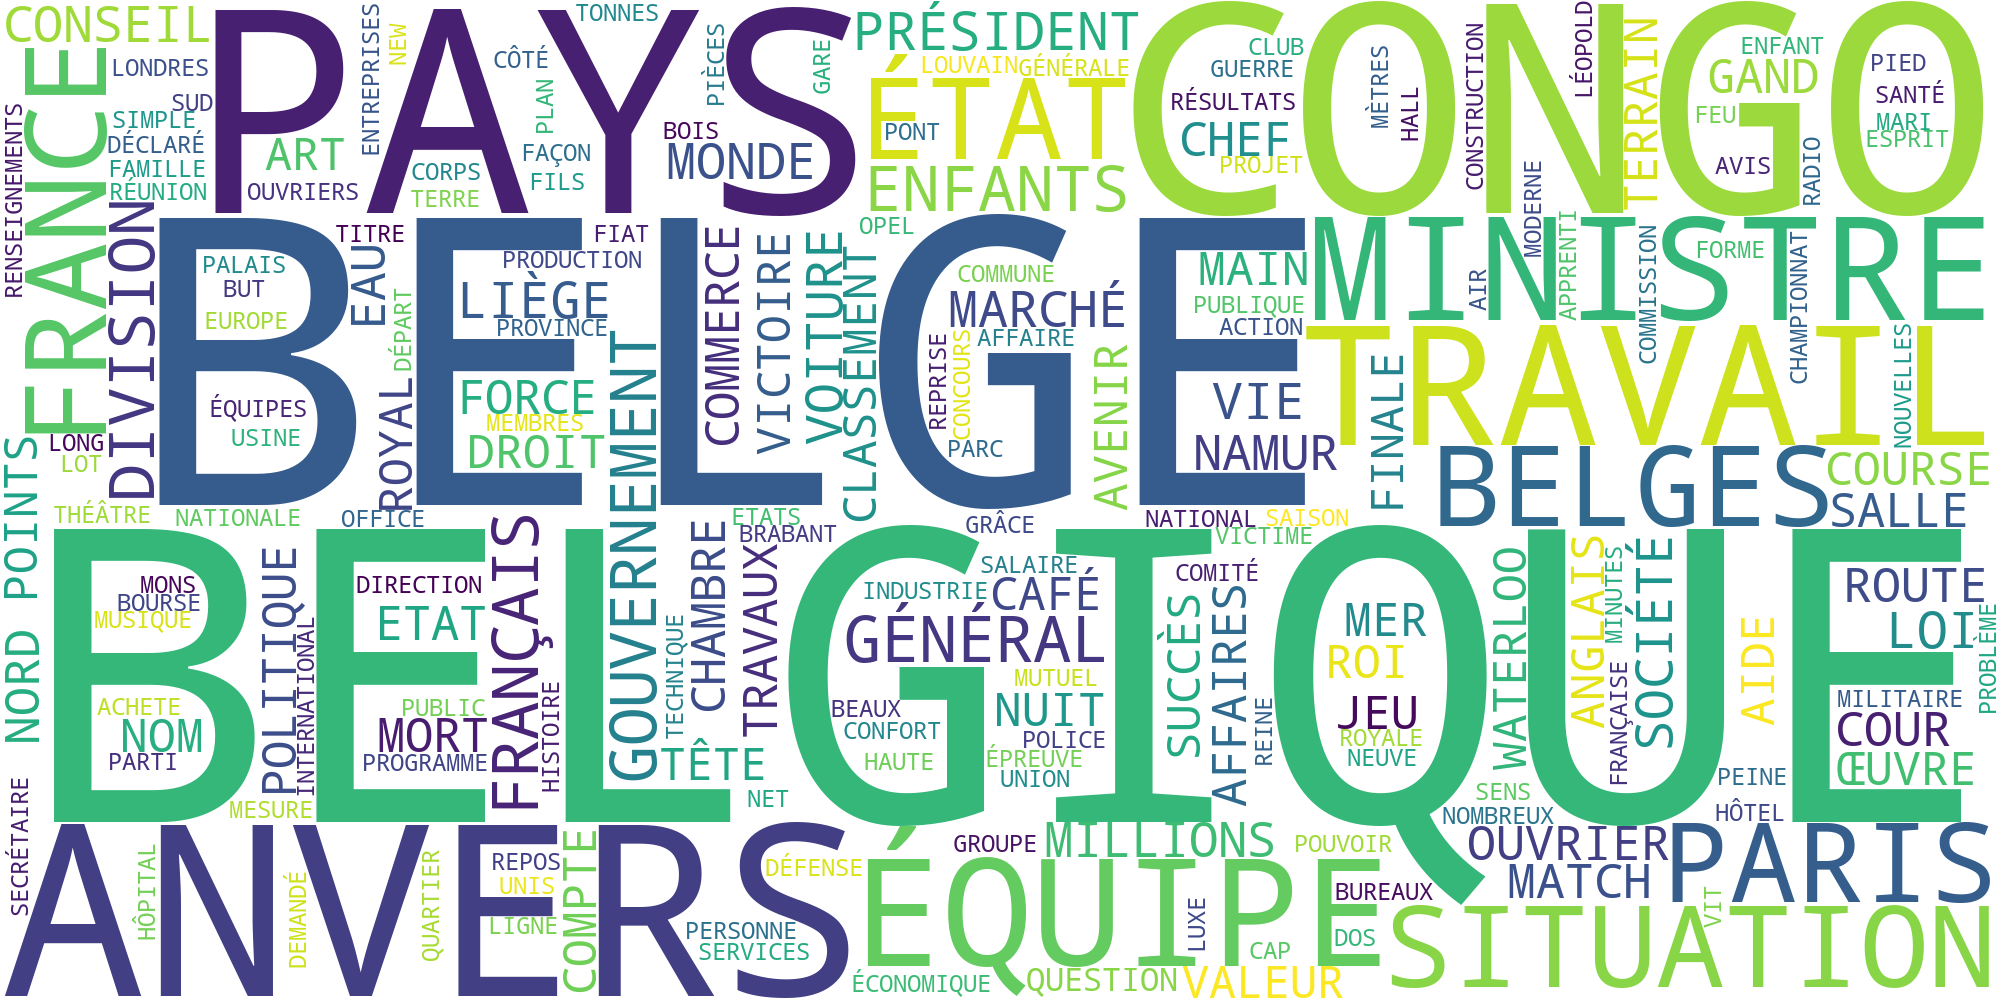

In [22]:
cloud = WordCloud(width=2000, height=1000, background_color='white').generate_from_frequencies(frequencies)
cloud.to_file(os.path.join(temp_path, f"{year}.png"))
Image(filename=os.path.join(temp_path, f"{year}.png"))

**Commentaire.** Le nuage confirme les chiffres. « BELGIQUE », « BELGE », « CONGO » et « PAYS » sont les plus gros mots. L'année 1960 est donc dominée, dans Le Soir, par la relation entre la Belgique et le Congo. Autour, on lit « GOUVERNEMENT », « MINISTRE », « SITUATION » et « POLITIQUE », qui renvoient à la crise. On lit aussi « TRAVAIL », « ÉQUIPE » et « MATCH », qui rappellent que le journal contient beaucoup d'annonces et de sport.

**Limites.** Certains mots apparaissent en double, par exemple « ÉTAT » et « ETAT », ou « BELGE » et « BELGES ». La fonction `clean_text` ne regroupe pas les formes d'un même mot. De plus, quelques mots viennent encore des annonces (« CONFORT », « LUXE », « OPEL », « FIAT »). Nous pourrions continuer à enrichir la liste, mais le sens général du nuage ne changerait plus.